In [1]:
# ============================================================
# NYC TAXI TRIP DURATION PROJECT
# 01 - EDA NOTEBOOK
# ============================================================

# ======================
# IMPORT LIBRARIES
# ======================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# ======================
# DISPLAY SETTINGS
# ======================

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# ======================
# PLOT SETTINGS
# ======================

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Cell 1 executed successfully: Libraries imported.")

Cell 1 executed successfully: Libraries imported.


In [2]:
# ============================================================
# LOAD DATASET
# ============================================================

from pathlib import Path

possible_paths = [
    Path("../data/nyc_taxi_trip_duration.csv"),
    Path("data/nyc_taxi_trip_duration.csv"),
    Path("./nyc_taxi_trip_duration.csv"),
]

file_path = None

for path in possible_paths:
    if path.exists():
        file_path = path
        break

if file_path is None:
    raise FileNotFoundError(
        "nyc_taxi_trip_duration.csv not found. "
        "Place it inside ../data/, data/, or the same folder as this notebook."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("File used:", file_path)

print("\nShape of Dataset:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Dataset loaded successfully.
File used: ..\data\nyc_taxi_trip_duration.csv

Shape of Dataset:
(729322, 11)

First 5 Rows:


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id1080784,2,2016-02-29 16:40:21,2016-02-29 16:47:01,1,-73.953918,40.778873,-73.963875,40.771164,N,400
1,id0889885,1,2016-03-11 23:35:37,2016-03-11 23:53:57,2,-73.988312,40.731743,-73.994751,40.694931,N,1100
2,id0857912,2,2016-02-21 17:59:33,2016-02-21 18:26:48,2,-73.997314,40.721458,-73.948029,40.774918,N,1635
3,id3744273,2,2016-01-05 09:44:31,2016-01-05 10:03:32,6,-73.961670,40.759720,-73.956779,40.780628,N,1141
4,id0232939,1,2016-02-17 06:42:23,2016-02-17 06:56:31,1,-74.017120,40.708469,-73.988182,40.740631,N,848


In [3]:
# ============================================================
# CELL 3 - DATASET OVERVIEW
# ============================================================

print("Dataset Information")
print("=" * 50)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

print("\nDataset Info:")
df.info()

Dataset Information

Column Names:
['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration']

Data Types:


id                        str
vendor_id               int64
pickup_datetime           str
dropoff_datetime          str
passenger_count         int64
pickup_longitude      float64
pickup_latitude       float64
dropoff_longitude     float64
dropoff_latitude      float64
store_and_fwd_flag        str
trip_duration           int64
dtype: object


Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 729322 entries, 0 to 729321
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  729322 non-null  str    
 1   vendor_id           729322 non-null  int64  
 2   pickup_datetime     729322 non-null  str    
 3   dropoff_datetime    729322 non-null  str    
 4   passenger_count     729322 non-null  int64  
 5   pickup_longitude    729322 non-null  float64
 6   pickup_latitude     729322 non-null  float64
 7   dropoff_longitude   729322 non-null  float64
 8   dropoff_latitude    729322 non-null  float64
 9   store_and_fwd_flag  729322 non-null  str    
 10  trip_duration       729322 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 94.6 MB


In [4]:
# ============================================================
# CELL 4 - BASIC STATISTICAL SUMMARY
# ============================================================

print("Statistical Summary of Numerical Columns")
print("=" * 60)

display(df.describe())

Statistical Summary of Numerical Columns


,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,729322.000000,729322.000000,729322.000000,729322.000000,729322.000000,729322.000000,7.293220e+05
mean,1.535403,1.662055,-73.973513,40.750919,-73.973422,40.751775,9.522291e+02
std,0.498745,1.312446,0.069754,0.033594,0.069588,0.036037,3.864626e+03
min,1.000000,0.000000,-121.933342,34.712234,-121.933304,32.181141,1.000000e+00
25%,1.000000,1.000000,-73.991859,40.737335,-73.991318,40.735931,3.970000e+02
50%,2.000000,1.000000,-73.981758,40.754070,-73.979759,40.754509,6.630000e+02
75%,2.000000,2.000000,-73.967361,40.768314,-73.963036,40.769741,1.075000e+03
max,2.000000,9.000000,-65.897385,51.881084,-65.897385,43.921028,1.939736e+06


In [5]:
# ============================================================
# CELL 5 - MISSING VALUES CHECK
# ============================================================

missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

display(missing_df)

,Missing Values,Missing Percentage
id,0,0.0
vendor_id,0,0.0
pickup_datetime,0,0.0
dropoff_datetime,0,0.0
passenger_count,0,0.0
pickup_longitude,0,0.0
pickup_latitude,0,0.0
dropoff_longitude,0,0.0
dropoff_latitude,0,0.0
store_and_fwd_flag,0,0.0


In [6]:
# ============================================================
# CELL 6 - DUPLICATE ROWS CHECK
# ============================================================

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [7]:
# ============================================================
# CELL 7 - TARGET COLUMN IDENTIFICATION
# ============================================================

target_column = "trip_duration"

print("Target Column:", target_column)
print("\nTarget Column Data Type:")
print(df[target_column].dtype)

print("\nTarget Column First 10 Values:")
display(df[target_column].head(10))

Target Column: trip_duration

Target Column Data Type:
int64

Target Column First 10 Values:


0     400
1    1100
2    1635
3    1141
4     848
5    1455
6     397
7    1101
8    1886
9    1429
Name: trip_duration, dtype: int64

In [8]:
# ============================================================
# CELL 8 - CONFIRM PROBLEM TYPE
# ============================================================

print("Problem Type: Regression")
print("Reason: trip_duration is a continuous numerical column.")

print("\nTarget Column Summary:")
display(df["trip_duration"].describe())

Problem Type: Regression
Reason: trip_duration is a continuous numerical column.

Target Column Summary:


count    7.293220e+05
mean     9.522291e+02
std      3.864626e+03
min      1.000000e+00
25%      3.970000e+02
50%      6.630000e+02
75%      1.075000e+03
max      1.939736e+06
Name: trip_duration, dtype: float64

In [9]:
# ============================================================
# CELL 9 - CONVERT DATETIME COLUMNS
# ============================================================

df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["dropoff_datetime"] = pd.to_datetime(df["dropoff_datetime"])

print("Datetime conversion completed.\n")

print(df[["pickup_datetime", "dropoff_datetime"]].dtypes)

Datetime conversion completed.

pickup_datetime     datetime64[us]
dropoff_datetime    datetime64[us]
dtype: object


In [10]:
# ============================================================
# CELL 10 - IDENTIFY COLUMN TYPES
# ============================================================

numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

datetime_columns = df.select_dtypes(include=["datetime64[ns]"]).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

print("\nDatetime Columns:")
print(datetime_columns)

Numerical Columns:
['vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'trip_duration']

Categorical Columns:
['id', 'store_and_fwd_flag']

Datetime Columns:
['pickup_datetime', 'dropoff_datetime']


In [11]:
# ============================================================
# CELL 11 - INVALID VALUES CHECK
# ============================================================

print("Checking invalid values...\n")

# Passenger count <= 0
invalid_passenger = df[df["passenger_count"] <= 0]

print("Invalid Passenger Count Rows:", len(invalid_passenger))

# Trip duration <= 0
invalid_duration = df[df["trip_duration"] <= 0]

print("Invalid Trip Duration Rows:", len(invalid_duration))

Checking invalid values...

Invalid Passenger Count Rows: 33
Invalid Trip Duration Rows: 0


In [12]:
# ============================================================
# CELL 12 - CREATE SAMPLE DATASET
# ============================================================

df_sample = df.sample(50000, random_state=42)

print("Sample dataset created successfully.")

print("Sample Shape:", df_sample.shape)

Sample dataset created successfully.
Sample Shape: (50000, 11)


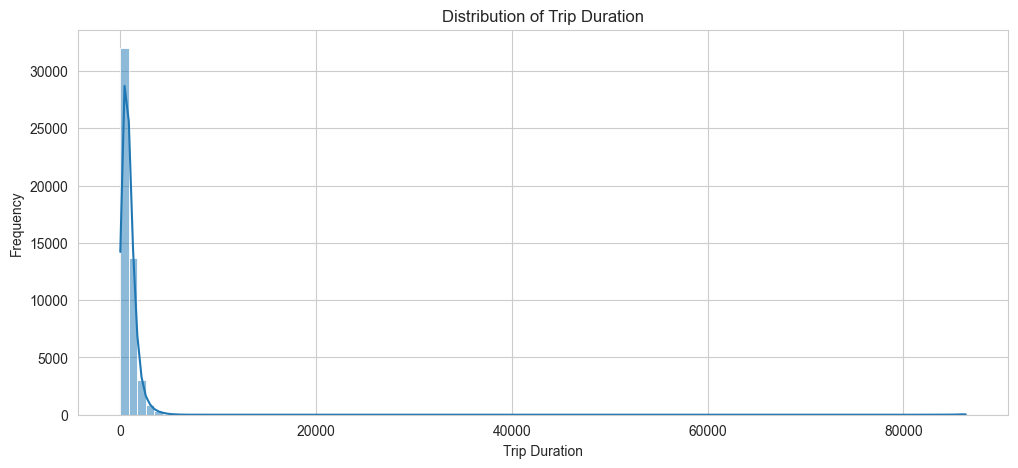

In [13]:
# ============================================================
# CELL 13 - TARGET VARIABLE DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 5))

sns.histplot(df_sample["trip_duration"], bins=100, kde=True)

plt.title("Distribution of Trip Duration")
plt.xlabel("Trip Duration")
plt.ylabel("Frequency")

plt.show()

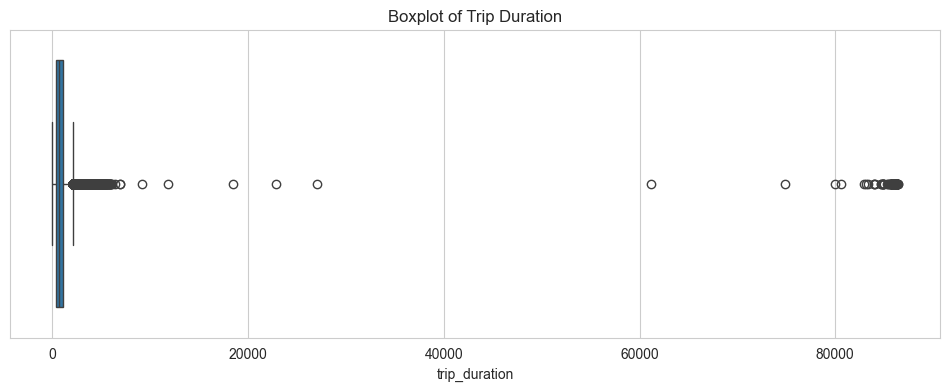

In [14]:
# ============================================================
# CELL 14 - BOXPLOT FOR TRIP DURATION
# ============================================================

plt.figure(figsize=(12, 4))

sns.boxplot(x=df_sample["trip_duration"])

plt.title("Boxplot of Trip Duration")

plt.show()

In [15]:
# ============================================================
# CELL 15 - SKEWNESS CHECK
# ============================================================

skewness = df["trip_duration"].skew()

print("Skewness of Trip Duration:", skewness)

Skewness of Trip Duration: 186.6784368781187


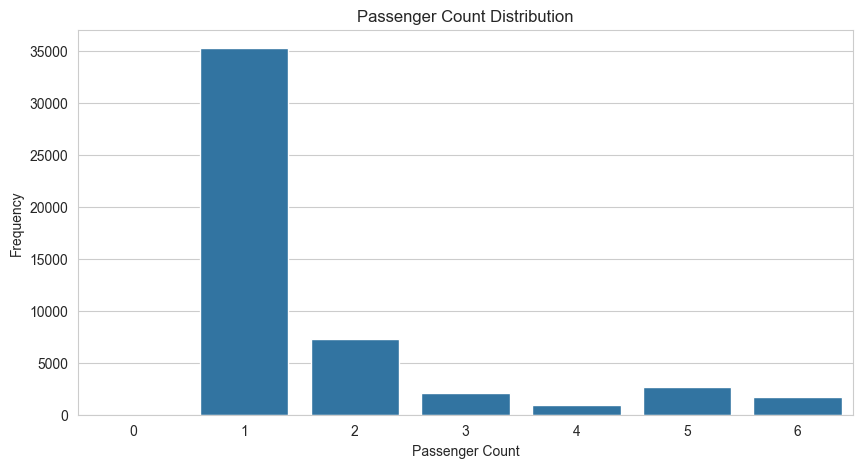

In [16]:
# ============================================================
# CELL 16 - PASSENGER COUNT DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.countplot(x=df_sample["passenger_count"])

plt.title("Passenger Count Distribution")
plt.xlabel("Passenger Count")
plt.ylabel("Frequency")

plt.show()

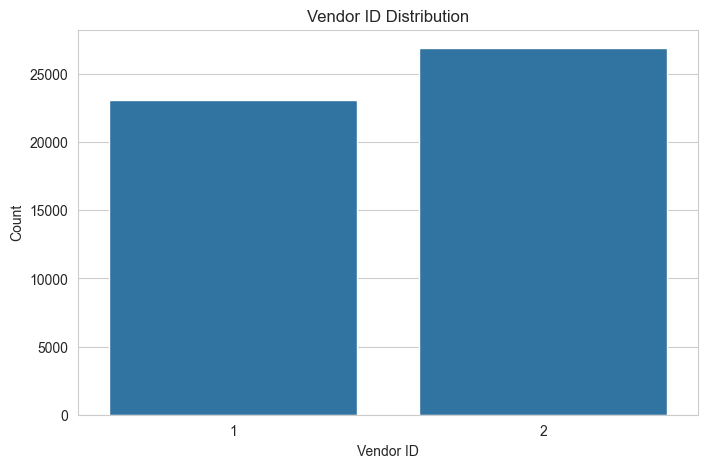

In [17]:
# ============================================================
# CELL 17 - VENDOR ID ANALYSIS
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(x=df_sample["vendor_id"])

plt.title("Vendor ID Distribution")
plt.xlabel("Vendor ID")
plt.ylabel("Count")

plt.show()

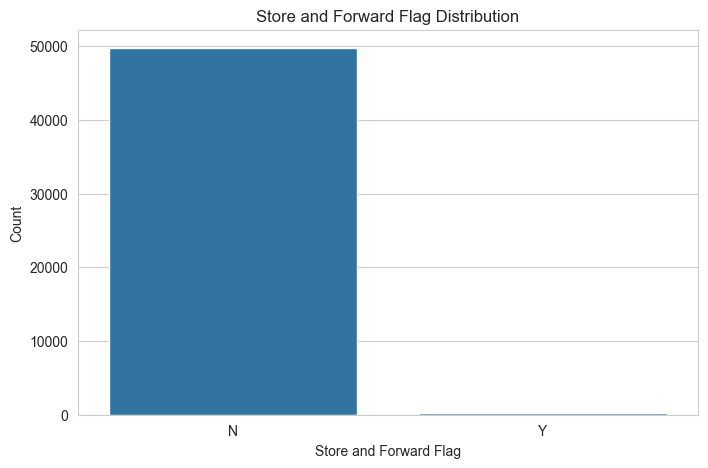

In [18]:
# ============================================================
# CELL 18 - STORE AND FORWARD FLAG ANALYSIS
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(x=df_sample["store_and_fwd_flag"])

plt.title("Store and Forward Flag Distribution")
plt.xlabel("Store and Forward Flag")
plt.ylabel("Count")

plt.show()

In [19]:
# ============================================================
# CELL 19 - CREATE EDA COPY
# ============================================================

eda_df = df.copy()

print("EDA copy created successfully.")
print("Shape:", eda_df.shape)

EDA copy created successfully.
Shape: (729322, 11)


In [20]:
# ============================================================
# CELL 20 - TEMPORARY DATETIME COLUMNS FOR EDA
# ============================================================

eda_df["pickup_hour"] = eda_df["pickup_datetime"].dt.hour
eda_df["pickup_day_name"] = eda_df["pickup_datetime"].dt.day_name()
eda_df["pickup_month"] = eda_df["pickup_datetime"].dt.month

print("Temporary datetime columns created for EDA only.")

display(eda_df[["pickup_datetime", "pickup_hour", "pickup_day_name", "pickup_month"]].head())

Temporary datetime columns created for EDA only.


,pickup_datetime,pickup_hour,pickup_day_name,pickup_month
0,2016-02-29 16:40:21,16,Monday,2
1,2016-03-11 23:35:37,23,Friday,3
2,2016-02-21 17:59:33,17,Sunday,2
3,2016-01-05 09:44:31,9,Tuesday,1
4,2016-02-17 06:42:23,6,Wednesday,2


In [21]:
# ============================================================
# CELL 20.1 - TEMPORARY DISTANCE FEATURE FOR EDA
# ============================================================

print("TEMPORARY DISTANCE FEATURE FOR EDA")
print("=" * 70)

def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return R * c


eda_df["trip_distance_km"] = haversine_distance(
    eda_df["pickup_latitude"],
    eda_df["pickup_longitude"],
    eda_df["dropoff_latitude"],
    eda_df["dropoff_longitude"],
)

print("Temporary trip_distance_km created for EDA only.")

display(
    eda_df[
        [
            "pickup_latitude",
            "pickup_longitude",
            "dropoff_latitude",
            "dropoff_longitude",
            "trip_distance_km",
            "trip_duration",
        ]
    ].head()
)

TEMPORARY DISTANCE FEATURE FOR EDA
Temporary trip_distance_km created for EDA only.


,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,trip_distance_km,trip_duration
0,40.778873,-73.953918,40.771164,-73.963875,1.199073,400
1,40.731743,-73.988312,40.694931,-73.994751,4.129111,1100
2,40.721458,-73.997314,40.774918,-73.948029,7.250753,1635
3,40.759720,-73.961670,40.780628,-73.956779,2.361097,1141
4,40.708469,-74.017120,40.740631,-73.988182,4.328534,848


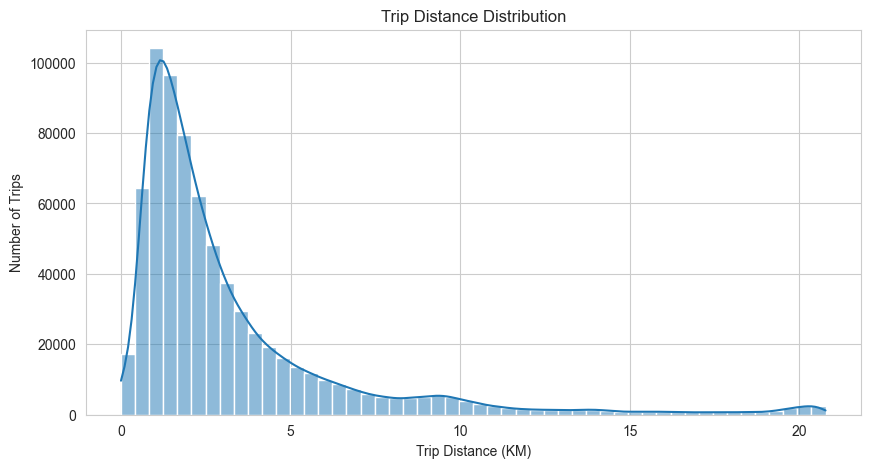

Inference:
Most trips are short-distance trips. Very long trips are rare and should be reviewed as possible outliers or special cases.


In [22]:
# ============================================================
# CELL 20.2 - TRIP DISTANCE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    eda_df[eda_df["trip_distance_km"] <= eda_df["trip_distance_km"].quantile(0.99)]["trip_distance_km"],
    bins=50,
    kde=True
)

plt.title("Trip Distance Distribution")
plt.xlabel("Trip Distance (KM)")
plt.ylabel("Number of Trips")

plt.show()

print("Inference:")
print("Most trips are short-distance trips. Very long trips are rare and should be reviewed as possible outliers or special cases.")

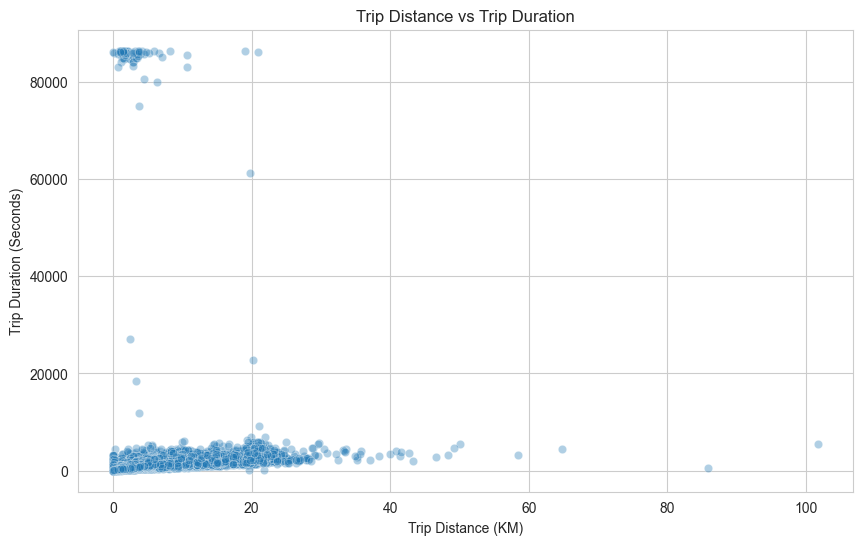

Inference:
Trip distance has a positive relationship with trip duration. Longer trips generally take more time, but traffic and route conditions create variation.


In [23]:
# ============================================================
# CELL 20.3 - DISTANCE VS TRIP DURATION
# ============================================================

sample_distance_df = eda_df.sample(
    min(50000, len(eda_df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_distance_df,
    x="trip_distance_km",
    y="trip_duration",
    alpha=0.35
)

plt.title("Trip Distance vs Trip Duration")
plt.xlabel("Trip Distance (KM)")
plt.ylabel("Trip Duration (Seconds)")

plt.show()

print("Inference:")
print("Trip distance has a positive relationship with trip duration. Longer trips generally take more time, but traffic and route conditions create variation.")

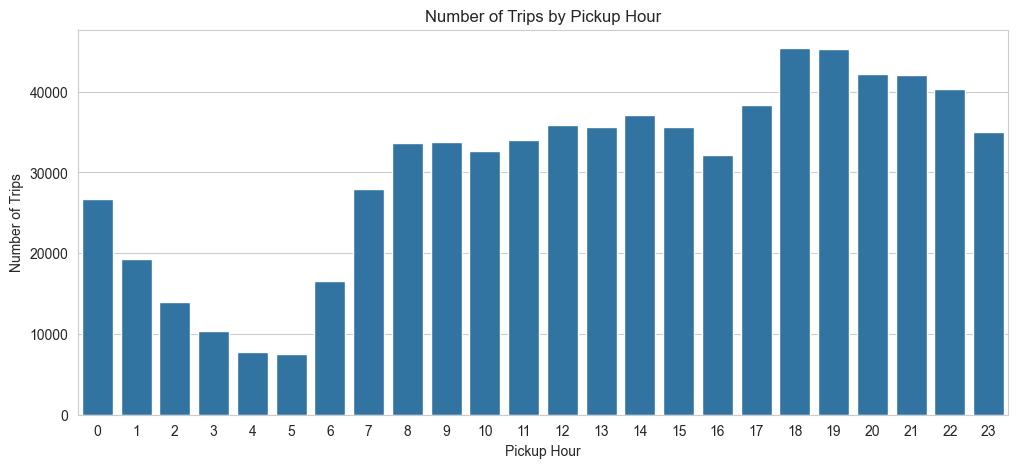

In [24]:
# ============================================================
# CELL 21 - UNIVARIATE ANALYSIS: TRIPS BY PICKUP HOUR
# ============================================================

plt.figure(figsize=(12, 5))

sns.countplot(data=eda_df, x="pickup_hour")

plt.title("Number of Trips by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Trips")

plt.show()

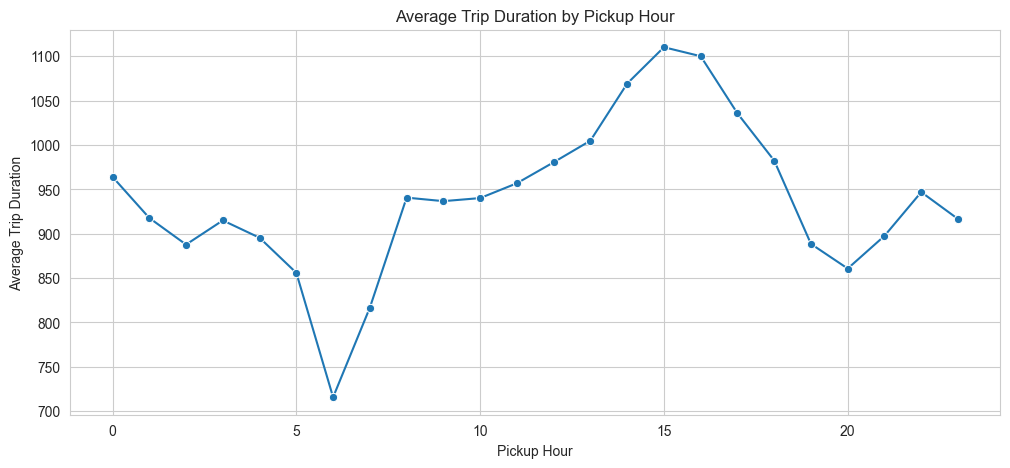

In [25]:
# ============================================================
# CELL 22 - BIVARIATE ANALYSIS:
# AVERAGE TRIP DURATION BY PICKUP HOUR
# ============================================================

hourly_duration = (
    eda_df.groupby("pickup_hour")["trip_duration"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_duration,
    x="pickup_hour",
    y="trip_duration",
    marker="o"
)

plt.title("Average Trip Duration by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Trip Duration")

plt.show()

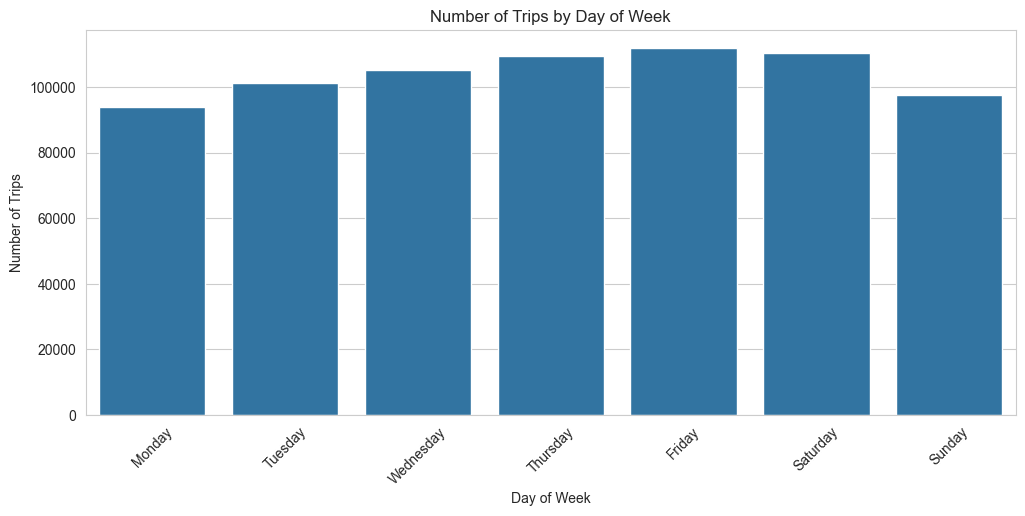

In [26]:
# ============================================================
# CELL 23 - UNIVARIATE ANALYSIS:
# TRIPS BY DAY OF WEEK
# ============================================================

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

plt.figure(figsize=(12, 5))

sns.countplot(
    data=eda_df,
    x="pickup_day_name",
    order=day_order
)

plt.title("Number of Trips by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Trips")

plt.xticks(rotation=45)

plt.show()

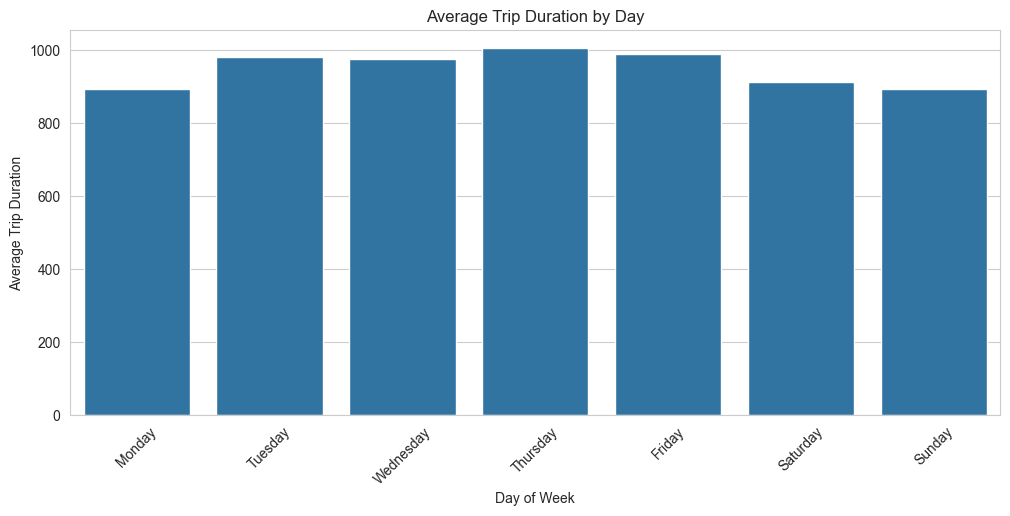

In [27]:
# ============================================================
# CELL 24 - BIVARIATE ANALYSIS:
# AVERAGE TRIP DURATION BY DAY
# ============================================================

daily_duration = (
    eda_df.groupby("pickup_day_name")["trip_duration"]
    .mean()
    .reindex(day_order)
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=daily_duration,
    x="pickup_day_name",
    y="trip_duration"
)

plt.title("Average Trip Duration by Day")
plt.xlabel("Day of Week")
plt.ylabel("Average Trip Duration")

plt.xticks(rotation=45)

plt.show()

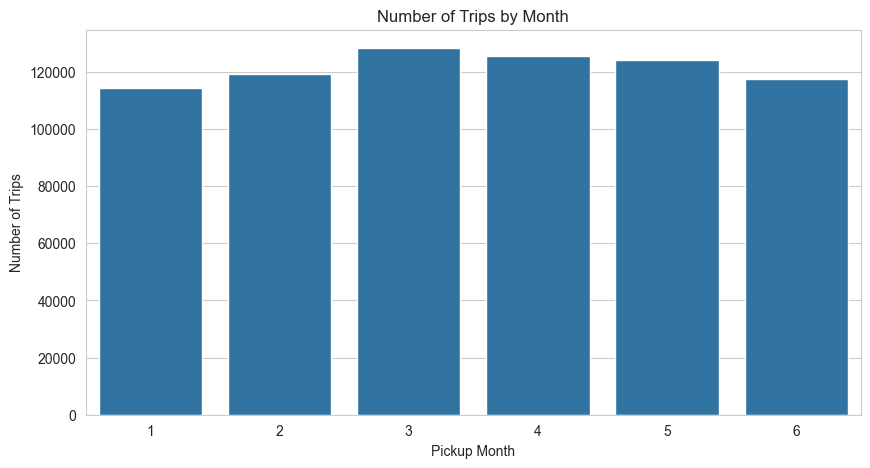

In [28]:
# ============================================================
# CELL 25 - UNIVARIATE ANALYSIS:
# TRIPS BY MONTH
# ============================================================

plt.figure(figsize=(10, 5))

sns.countplot(data=eda_df, x="pickup_month")

plt.title("Number of Trips by Month")
plt.xlabel("Pickup Month")
plt.ylabel("Number of Trips")

plt.show()

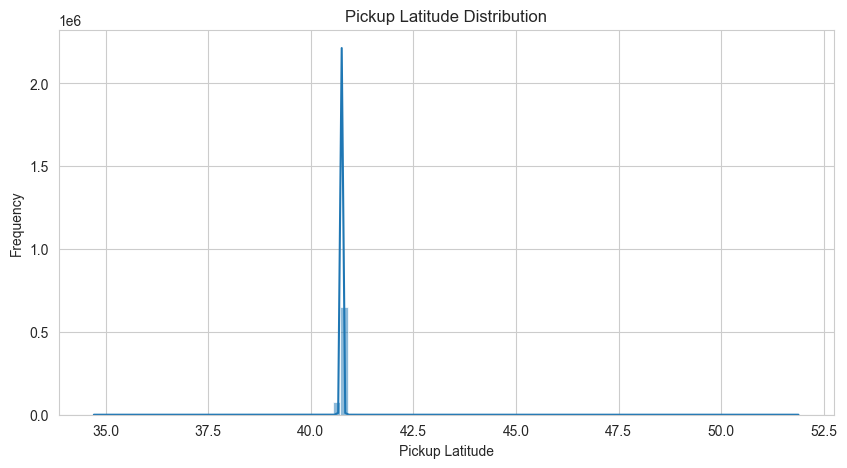

In [29]:
# ============================================================
# CELL 26 - PICKUP LATITUDE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(eda_df["pickup_latitude"], bins=100, kde=True)

plt.title("Pickup Latitude Distribution")
plt.xlabel("Pickup Latitude")
plt.ylabel("Frequency")

plt.show()

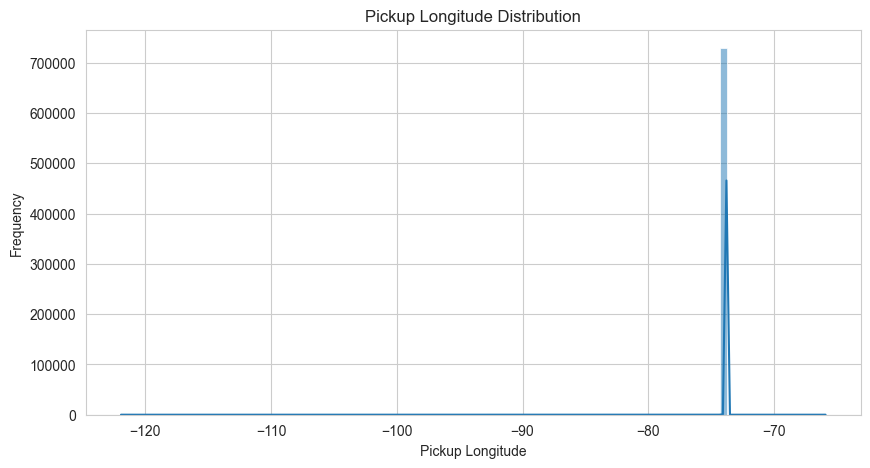

In [30]:
# ============================================================
# CELL 27 - PICKUP LONGITUDE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(eda_df["pickup_longitude"], bins=100, kde=True)

plt.title("Pickup Longitude Distribution")
plt.xlabel("Pickup Longitude")
plt.ylabel("Frequency")

plt.show()

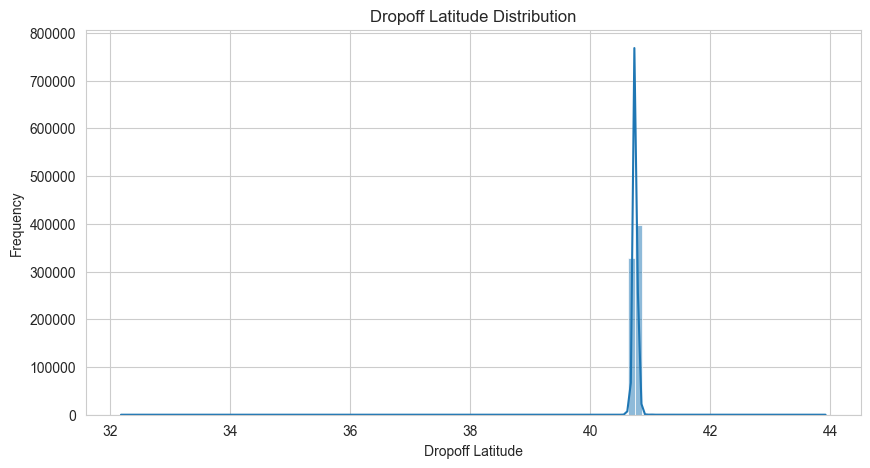

In [31]:
# ============================================================
# CELL 28 - DROPOFF LATITUDE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(eda_df["dropoff_latitude"], bins=100, kde=True)

plt.title("Dropoff Latitude Distribution")
plt.xlabel("Dropoff Latitude")
plt.ylabel("Frequency")

plt.show()

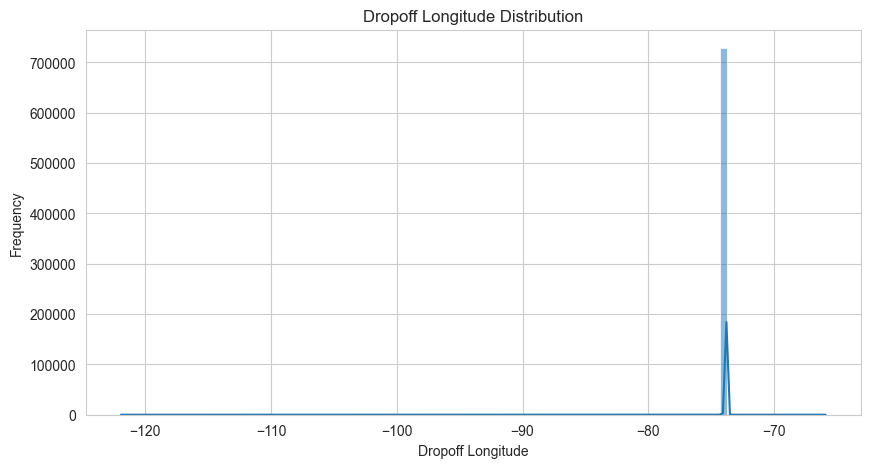

In [32]:
# ============================================================
# CELL 29 - DROPOFF LONGITUDE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(eda_df["dropoff_longitude"], bins=100, kde=True)

plt.title("Dropoff Longitude Distribution")
plt.xlabel("Dropoff Longitude")
plt.ylabel("Frequency")

plt.show()

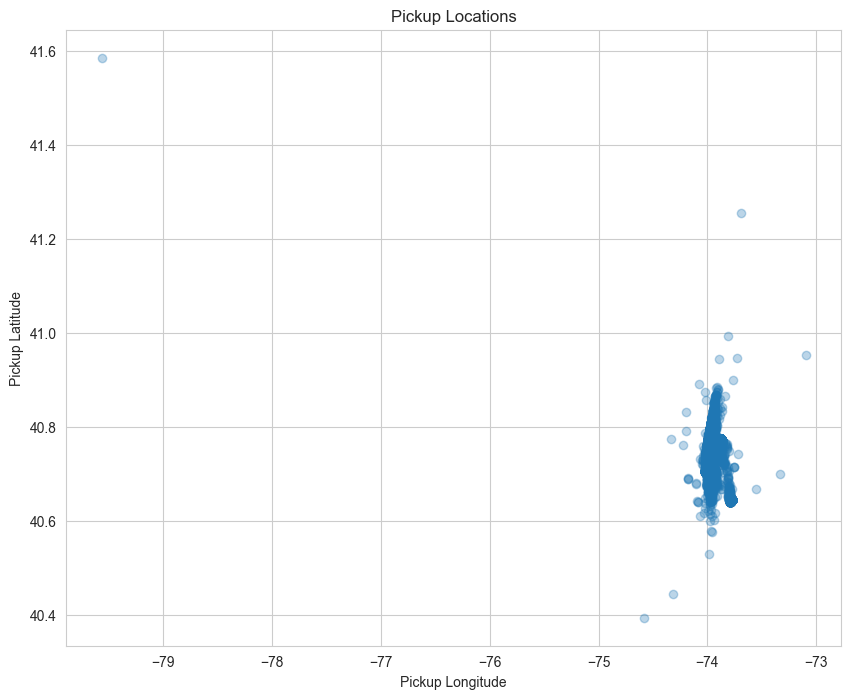

In [33]:
# ============================================================
# CELL 30 - PICKUP LOCATION SCATTERPLOT
# ============================================================

plt.figure(figsize=(10, 8))

plt.scatter(
    df_sample["pickup_longitude"],
    df_sample["pickup_latitude"],
    alpha=0.3
)

plt.title("Pickup Locations")
plt.xlabel("Pickup Longitude")
plt.ylabel("Pickup Latitude")

plt.show()

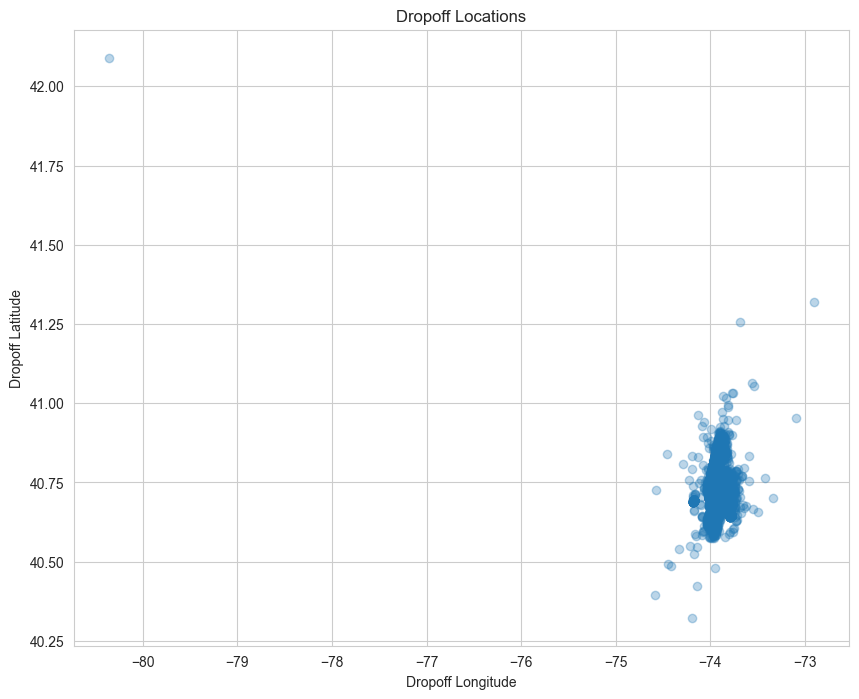

In [34]:
# ============================================================
# CELL 31 - DROPOFF LOCATION SCATTERPLOT
# ============================================================

plt.figure(figsize=(10, 8))

plt.scatter(
    df_sample["dropoff_longitude"],
    df_sample["dropoff_latitude"],
    alpha=0.3
)

plt.title("Dropoff Locations")
plt.xlabel("Dropoff Longitude")
plt.ylabel("Dropoff Latitude")

plt.show()

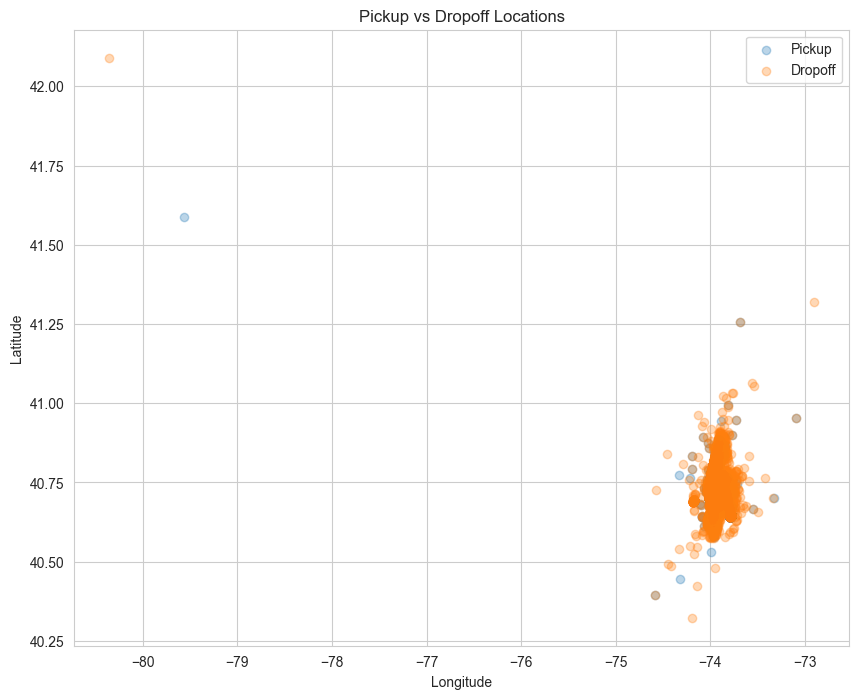

In [35]:
# ============================================================
# CELL 32 - PICKUP VS DROPOFF LOCATIONS
# ============================================================

plt.figure(figsize=(10, 8))

plt.scatter(
    df_sample["pickup_longitude"],
    df_sample["pickup_latitude"],
    alpha=0.3,
    label="Pickup"
)

plt.scatter(
    df_sample["dropoff_longitude"],
    df_sample["dropoff_latitude"],
    alpha=0.3,
    label="Dropoff"
)

plt.title("Pickup vs Dropoff Locations")

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend()

plt.show()

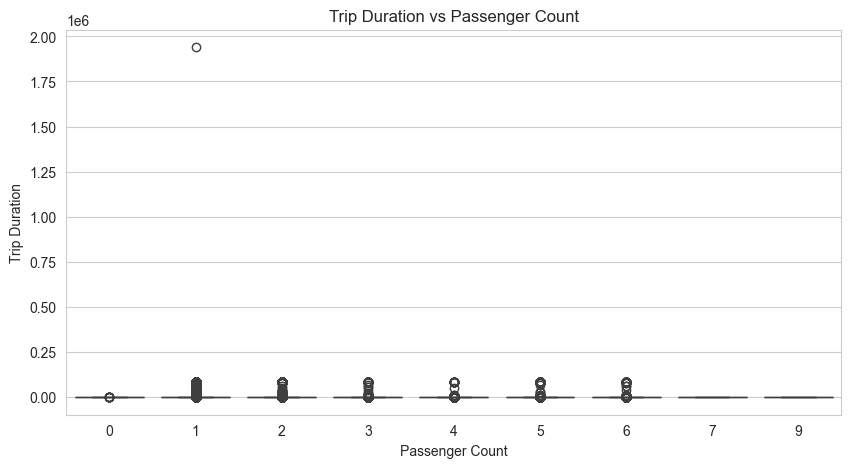

In [36]:
# ============================================================
# CELL 33 - TRIP DURATION VS PASSENGER COUNT
# ============================================================

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=eda_df,
    x="passenger_count",
    y="trip_duration"
)

plt.title("Trip Duration vs Passenger Count")

plt.xlabel("Passenger Count")
plt.ylabel("Trip Duration")

plt.show()

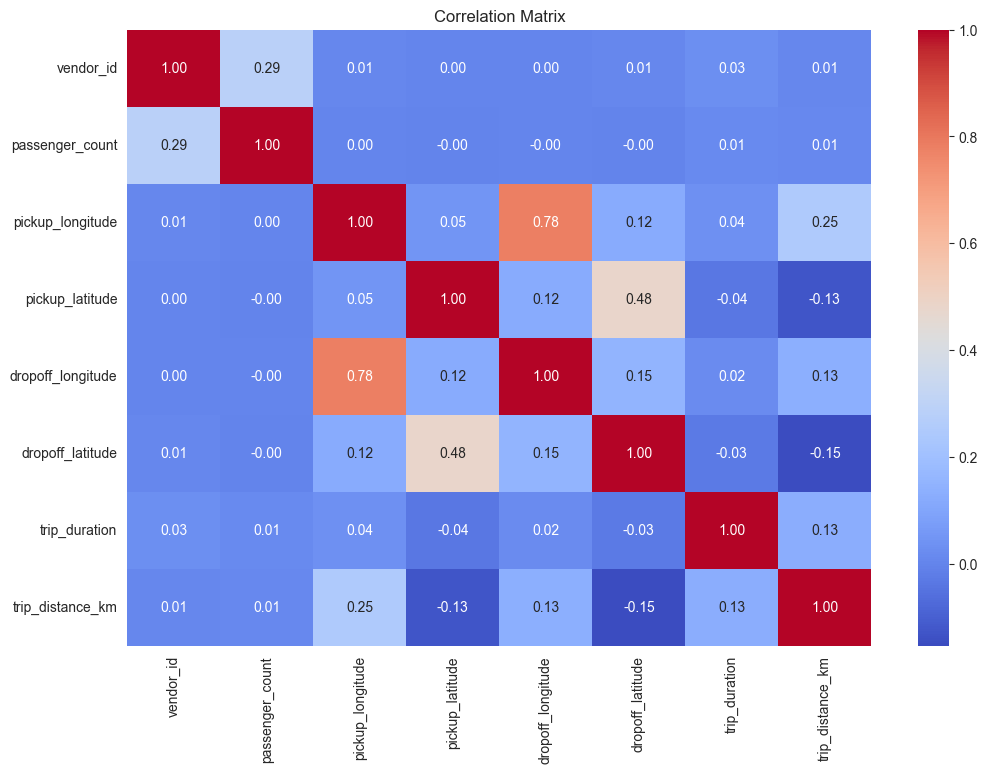

In [37]:
# ============================================================
# CELL 34 - CORRELATION MATRIX
# ============================================================

numerical_df = eda_df.select_dtypes(
    include=["int64", "float64"]
)

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [38]:
# ============================================================
# CELL 35 - CORRELATION WITH TARGET COLUMN
# ============================================================

target_correlation = (
    correlation_matrix["trip_duration"]
    .sort_values(ascending=False)
)

print("Correlation with Trip Duration")
print("=" * 50)

display(target_correlation)

Correlation with Trip Duration


trip_duration        1.000000
trip_distance_km     0.125772
pickup_longitude     0.035447
vendor_id            0.027752
dropoff_longitude    0.020664
passenger_count      0.013022
dropoff_latitude    -0.028283
pickup_latitude     -0.038163
Name: trip_duration, dtype: float64

In [39]:
# ============================================================
# CELL 36 - OUTLIER DETECTION USING IQR
# ============================================================

Q1 = eda_df["trip_duration"].quantile(0.25)
Q3 = eda_df["trip_duration"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = eda_df[
    (eda_df["trip_duration"] < lower_bound) |
    (eda_df["trip_duration"] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nNumber of Outliers:", len(outliers))

Lower Bound: -620.0
Upper Bound: 2092.0

Number of Outliers: 36963


In [40]:
# ============================================================
# CELL 37 - OUTLIER PERCENTAGE
# ============================================================

outlier_percentage = (
    len(outliers) / len(eda_df)
) * 100

print("Outlier Percentage:", round(outlier_percentage, 2), "%")

Outlier Percentage: 5.07 %


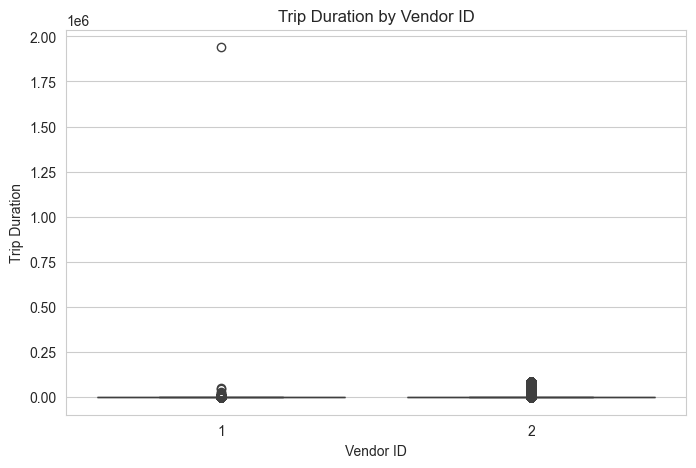

In [41]:
# ============================================================
# CELL 38 - BIVARIATE ANALYSIS: VENDOR ID VS TRIP DURATION
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="vendor_id",
    y="trip_duration"
)

plt.title("Trip Duration by Vendor ID")
plt.xlabel("Vendor ID")
plt.ylabel("Trip Duration")

plt.show()

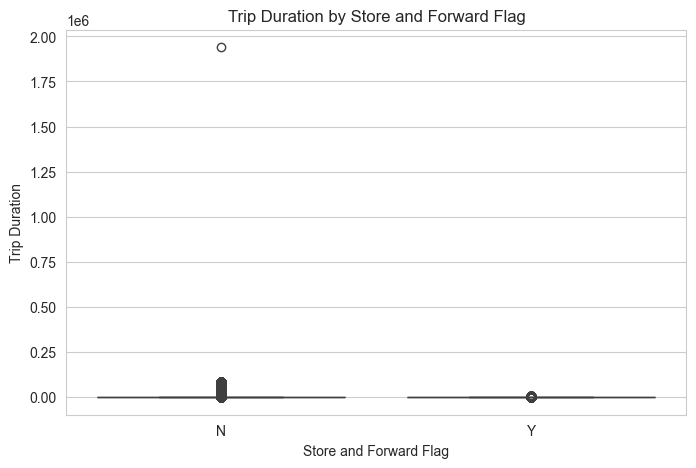

In [42]:
# ============================================================
# CELL 39 - BIVARIATE ANALYSIS: STORE AND FORWARD FLAG VS TRIP DURATION
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="store_and_fwd_flag",
    y="trip_duration"
)

plt.title("Trip Duration by Store and Forward Flag")
plt.xlabel("Store and Forward Flag")
plt.ylabel("Trip Duration")

plt.show()

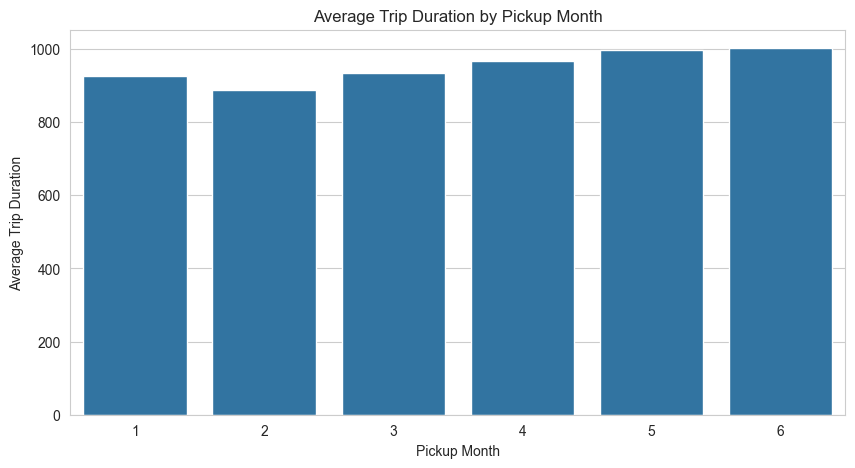

In [43]:
# ============================================================
# CELL 40 - BIVARIATE ANALYSIS: PICKUP MONTH VS TRIP DURATION
# ============================================================

monthly_duration = (
    eda_df.groupby("pickup_month")["trip_duration"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_duration,
    x="pickup_month",
    y="trip_duration"
)

plt.title("Average Trip Duration by Pickup Month")
plt.xlabel("Pickup Month")
plt.ylabel("Average Trip Duration")

plt.show()

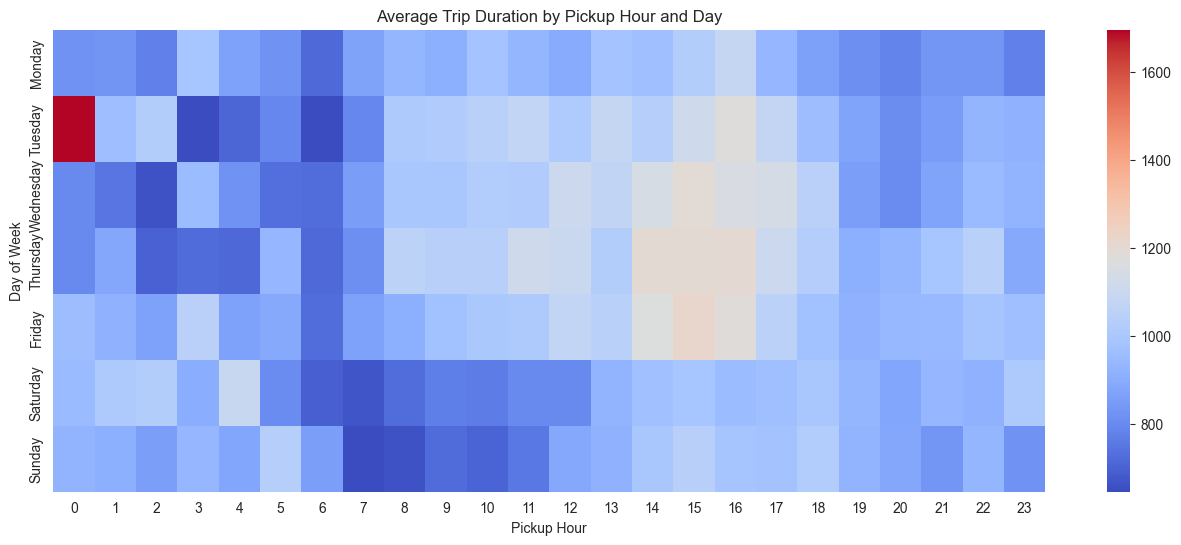

In [44]:
# ============================================================
# CELL 41 - MULTIVARIATE ANALYSIS: PICKUP HOUR AND DAY HEATMAP
# ============================================================

hour_day_table = eda_df.pivot_table(
    values="trip_duration",
    index="pickup_day_name",
    columns="pickup_hour",
    aggfunc="mean"
)

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

hour_day_table = hour_day_table.reindex(day_order)

plt.figure(figsize=(16, 6))

sns.heatmap(
    hour_day_table,
    cmap="coolwarm"
)

plt.title("Average Trip Duration by Pickup Hour and Day")
plt.xlabel("Pickup Hour")
plt.ylabel("Day of Week")

plt.show()

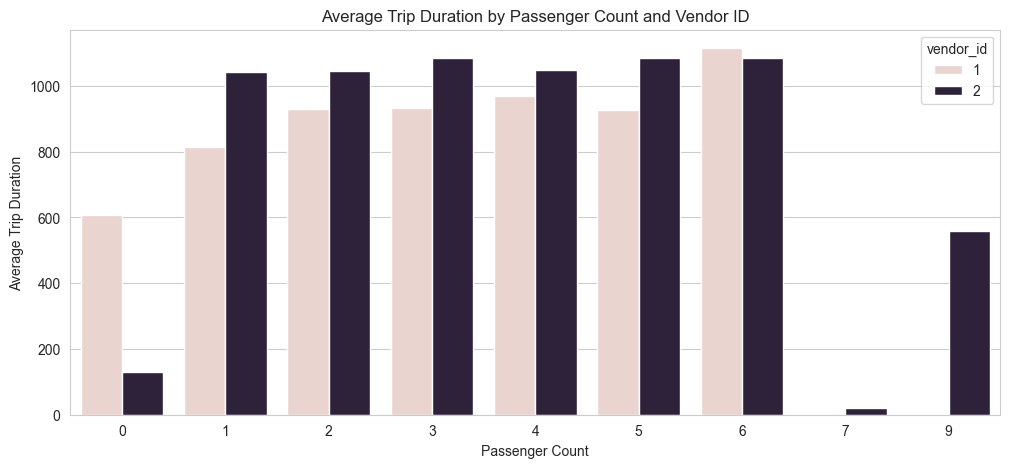

In [45]:
# ============================================================
# CELL 42 - MULTIVARIATE ANALYSIS: PASSENGER COUNT, VENDOR ID AND TRIP DURATION
# ============================================================

passenger_vendor_duration = (
    eda_df.groupby(["passenger_count", "vendor_id"])["trip_duration"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=passenger_vendor_duration,
    x="passenger_count",
    y="trip_duration",
    hue="vendor_id"
)

plt.title("Average Trip Duration by Passenger Count and Vendor ID")
plt.xlabel("Passenger Count")
plt.ylabel("Average Trip Duration")

plt.show()

In [46]:
# ============================================================
# CELL 43 - NYC COORDINATE BOUNDARY CHECK
# ============================================================

nyc_boundary_df = eda_df[
    (eda_df["pickup_latitude"].between(40.5, 41.0)) &
    (eda_df["pickup_longitude"].between(-74.3, -73.6)) &
    (eda_df["dropoff_latitude"].between(40.5, 41.0)) &
    (eda_df["dropoff_longitude"].between(-74.3, -73.6))
]

outside_boundary_count = len(eda_df) - len(nyc_boundary_df)

print("Rows inside approximate NYC boundary:", len(nyc_boundary_df))
print("Rows outside approximate NYC boundary:", outside_boundary_count)

print("\nInference:")
print("Some trips may have coordinates outside the expected NYC area. These should be reviewed during feature engineering.")

Rows inside approximate NYC boundary: 729021
Rows outside approximate NYC boundary: 301

Inference:
Some trips may have coordinates outside the expected NYC area. These should be reviewed during feature engineering.


In [47]:
# ============================================================
# CELL 44 - BUSINESS INSIGHTS
# ============================================================

print("""
BUSINESS INSIGHTS
==================================================

1. Trip duration is highly right-skewed.
2. Outliers exist in trip duration.
3. Trip demand changes across hours and weekdays.
4. Pickup and dropoff locations are concentrated.
5. Passenger count distribution is imbalanced.
6. Datetime columns contain useful temporal patterns.
7. Location columns may help create distance features.
8. Rush-hour patterns are visible in trip timings.
9. Correlation between existing features is low/moderate.
10. Feature engineering will be important for model performance.
""")


BUSINESS INSIGHTS

1. Trip duration is highly right-skewed.
2. Outliers exist in trip duration.
3. Trip demand changes across hours and weekdays.
4. Pickup and dropoff locations are concentrated.
5. Passenger count distribution is imbalanced.
6. Datetime columns contain useful temporal patterns.
7. Location columns may help create distance features.
8. Rush-hour patterns are visible in trip timings.
9. Correlation between existing features is low/moderate.
10. Feature engineering will be important for model performance.



In [48]:
# ============================================================
# CELL 45 - FEATURE ENGINEERING RECOMMENDATIONS
# ============================================================

print("""
FEATURE ENGINEERING RECOMMENDATIONS
==================================================

1. Extract hour, day, month, and weekday features from pickup_datetime.
2. Create weekend, rush-hour, office-hour, and late-night indicators.
3. Create trip distance using the Haversine formula.
4. Create Manhattan-style distance because NYC roads follow a grid-like pattern.
5. Create airport-related features for pickup and dropoff locations.
6. Create location cluster features from pickup and dropoff coordinates.
7. Apply log transformation on the target column because trip_duration is right-skewed.
8. Handle outliers carefully instead of deleting them blindly.
9. Encode categorical variables such as vendor_id and store_and_fwd_flag.
10. Scale numerical features if required by the model.
11. Detect and prevent data leakage before model building.
12. Use average speed only for analysis or data quality checking, not as a model input.
""")


FEATURE ENGINEERING RECOMMENDATIONS

1. Extract hour, day, month, and weekday features from pickup_datetime.
2. Create weekend, rush-hour, office-hour, and late-night indicators.
3. Create trip distance using the Haversine formula.
4. Create Manhattan-style distance because NYC roads follow a grid-like pattern.
5. Create airport-related features for pickup and dropoff locations.
6. Create location cluster features from pickup and dropoff coordinates.
7. Apply log transformation on the target column because trip_duration is right-skewed.
8. Handle outliers carefully instead of deleting them blindly.
9. Encode categorical variables such as vendor_id and store_and_fwd_flag.
10. Scale numerical features if required by the model.
11. Detect and prevent data leakage before model building.
12. Use average speed only for analysis or data quality checking, not as a model input.



In [49]:
# ============================================================
# CELL 46 - EDA CONCLUSION
# ============================================================

print("""
EDA CONCLUSION
==================================================

EDA successfully completed for NYC Taxi Trip Duration dataset.

Main observations:
- Dataset is large and feature-rich.
- Target variable contains skewness and outliers.
- Time-based patterns strongly affect trip duration.
- Location features are important.
- Passenger count has limited variation.
- Dataset is suitable for advanced feature engineering.

Next Step:
Proceed to Feature Engineering Notebook.
""")


EDA CONCLUSION

EDA successfully completed for NYC Taxi Trip Duration dataset.

Main observations:
- Dataset is large and feature-rich.
- Target variable contains skewness and outliers.
- Time-based patterns strongly affect trip duration.
- Location features are important.
- Passenger count has limited variation.
- Dataset is suitable for advanced feature engineering.

Next Step:
Proceed to Feature Engineering Notebook.



In [50]:
# ============================================================
# CELL 47 - GENERATE PROPER WORD EDA REPORT
# ============================================================

import os
from docx import Document
from docx.shared import Pt
from docx.enum.text import WD_PARAGRAPH_ALIGNMENT

# Create reports folder if not exists
os.makedirs("../reports", exist_ok=True)

# Create Word document
doc = Document()

# ============================================================
# TITLE
# ============================================================

title = doc.add_heading("Exploratory Data Analysis Report", level=1)
title.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER

subtitle = doc.add_heading("NYC Taxi Trip Duration Dataset", level=2)
subtitle.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER

# ============================================================
# 1. PROJECT OVERVIEW
# ============================================================

doc.add_heading("1. Project Overview", level=2)

doc.add_paragraph(
    "This report presents the exploratory data analysis of the NYC Taxi Trip Duration dataset. "
    "The purpose of this EDA is to understand the dataset, check data quality, study trip behavior, "
    "identify relationships with trip duration, and extract business insights."
)

doc.add_paragraph(
    "EDA does not treat or transform the data permanently. It only identifies patterns, issues, "
    "and possible actions. The actual treatment will be performed later in the Feature Engineering notebook."
)

# ============================================================
# 2. DATASET OVERVIEW
# ============================================================

doc.add_heading("2. Dataset Overview", level=2)

doc.add_paragraph(
    f"The dataset contains {df.shape[0]:,} rows and {df.shape[1]} columns. "
    "Each row represents one taxi trip."
)

table = doc.add_table(rows=1, cols=2)
table.style = "Table Grid"

hdr = table.rows[0].cells
hdr[0].text = "Column"
hdr[1].text = "Meaning"

column_meanings = {
    "id": "Unique trip ID",
    "vendor_id": "Taxi vendor/provider ID",
    "pickup_datetime": "Date and time when the trip started",
    "dropoff_datetime": "Date and time when the trip ended",
    "passenger_count": "Number of passengers in the trip",
    "pickup_longitude": "Longitude of pickup location",
    "pickup_latitude": "Latitude of pickup location",
    "dropoff_longitude": "Longitude of dropoff location",
    "dropoff_latitude": "Latitude of dropoff location",
    "store_and_fwd_flag": "Whether trip data was stored before forwarding",
    "trip_duration": "Duration of the trip in seconds"
}

for col in df.columns:
    row = table.add_row().cells
    row[0].text = col
    row[1].text = column_meanings.get(col, "Column meaning not defined")

# ============================================================
# 3. TARGET COLUMN AND PROBLEM TYPE
# ============================================================

doc.add_heading("3. Target Column and Problem Type", level=2)

doc.add_paragraph(
    "The target column is trip_duration. The trip_duration column represents the total duration "
    "of a taxi trip in seconds. Since this value is continuous and numerical, the dataset is suitable "
    "for a regression problem."
)

# ============================================================
# 4. DATA QUALITY SUMMARY
# ============================================================

doc.add_heading("4. Data Quality Summary", level=2)

missing_total = df.isnull().sum().sum()
duplicate_total = df.duplicated().sum()
invalid_passenger_count = df[df["passenger_count"] <= 0].shape[0]
invalid_trip_duration = df[df["trip_duration"] <= 0].shape[0]

quality_table = doc.add_table(rows=1, cols=2)
quality_table.style = "Table Grid"

hdr = quality_table.rows[0].cells
hdr[0].text = "Check"
hdr[1].text = "Finding"

quality_rows = [
    ("Missing values", f"{missing_total} missing values found"),
    ("Duplicate rows", f"{duplicate_total} duplicate rows found"),
    ("Invalid passenger_count values", f"{invalid_passenger_count} invalid values found"),
    ("Invalid trip_duration values", f"{invalid_trip_duration} invalid values found"),
    ("Datetime conversion", "pickup_datetime and dropoff_datetime converted successfully"),
    ("Target distribution", "trip_duration is right-skewed")
]

for check, finding in quality_rows:
    row = quality_table.add_row().cells
    row[0].text = check
    row[1].text = finding

doc.add_paragraph(
    "Inference: The dataset is suitable for analysis. However, trip_duration has skewness and outliers, "
    "so it should be reviewed carefully during feature engineering."
)

# ============================================================
# 5. UNIVARIATE ANALYSIS SUMMARY
# ============================================================

doc.add_heading("5. Univariate Analysis Summary", level=2)

doc.add_paragraph(
    "Univariate analysis was performed to study each column individually. Numerical columns were studied "
    "using distributions, statistical summaries, skewness checks, and boxplots. Categorical columns were "
    "studied using frequency counts and countplots."
)

uni_table = doc.add_table(rows=1, cols=2)
uni_table.style = "Table Grid"

hdr = uni_table.rows[0].cells
hdr[0].text = "Feature / Area"
hdr[1].text = "Observation"

uni_rows = [
    ("trip_duration", "Right-skewed distribution with outliers"),
    ("passenger_count", "Most trips have a small number of passengers"),
    ("vendor_id", "Trips are distributed across vendors"),
    ("store_and_fwd_flag", "Highly imbalanced category distribution"),
    ("pickup_hour", "Trip demand changes across the day"),
    ("pickup_day_name", "Trip count varies across weekdays"),
    ("pickup_month", "Monthly trip distribution shows time-based variation")
]

for feature, observation in uni_rows:
    row = uni_table.add_row().cells
    row[0].text = feature
    row[1].text = observation

doc.add_paragraph(
    "Inference: Trip behavior is not uniform. Time-based columns show clear demand variation, "
    "which indicates that datetime-based feature creation will be useful later."
)

# ============================================================
# 6. BIVARIATE ANALYSIS SUMMARY
# ============================================================

doc.add_heading("6. Bivariate Analysis Summary", level=2)

doc.add_paragraph(
    "Bivariate analysis was performed to understand how different variables relate to trip_duration."
)

bi_table = doc.add_table(rows=1, cols=2)
bi_table.style = "Table Grid"

hdr = bi_table.rows[0].cells
hdr[0].text = "Relationship"
hdr[1].text = "Observation"

bi_rows = [
    ("pickup_hour vs trip_duration", "Average trip duration changes across different pickup hours"),
    ("pickup_day_name vs trip_duration", "Average duration varies across days of the week"),
    ("passenger_count vs trip_duration", "Passenger count does not show a strong direct relationship"),
    ("vendor_id vs trip_duration", "Vendor impact should be checked later during modeling"),
    ("store_and_fwd_flag vs trip_duration", "Imbalanced category may have limited impact")
]

for relation, observation in bi_rows:
    row = bi_table.add_row().cells
    row[0].text = relation
    row[1].text = observation

doc.add_paragraph(
    "Inference: Time-related variables appear more useful than passenger count for explaining trip duration. "
    "This supports the need for detailed datetime feature engineering."
)

# ============================================================
# 7. MULTIVARIATE ANALYSIS SUMMARY
# ============================================================

doc.add_heading("7. Multivariate Analysis Summary", level=2)

doc.add_paragraph(
    "Multivariate analysis was performed using correlation analysis and combined visual patterns. "
    "The correlation heatmap helped understand relationships between numerical variables."
)

doc.add_paragraph(
    "Inference: Raw numerical features alone do not explain trip_duration strongly. Latitude and longitude "
    "need to be converted into meaningful distance-based features before modeling."
)

# ============================================================
# 8. LOCATION ANALYSIS SUMMARY
# ============================================================

doc.add_heading("8. Location Analysis Summary", level=2)

location_table = doc.add_table(rows=1, cols=2)
location_table.style = "Table Grid"

hdr = location_table.rows[0].cells
hdr[0].text = "Location Area"
hdr[1].text = "Observation"

location_rows = [
    ("Pickup coordinates", "Pickup points are geographically concentrated"),
    ("Dropoff coordinates", "Dropoff points are also geographically concentrated"),
    ("Raw latitude/longitude", "Not directly meaningful for regression without feature creation"),
    ("Business meaning", "Location strongly affects travel time and distance")
]

for area, obs in location_rows:
    row = location_table.add_row().cells
    row[0].text = area
    row[1].text = obs

doc.add_paragraph(
    "Inference: Location is important, but raw coordinates are not enough. Haversine distance and "
    "location-based features should be created in the Feature Engineering notebook."
)

# ============================================================
# 9. OUTLIER AND SKEWNESS SUMMARY
# ============================================================

doc.add_heading("9. Outlier and Skewness Summary", level=2)

skewness_value = df["trip_duration"].skew()

Q1 = df["trip_duration"].quantile(0.25)
Q3 = df["trip_duration"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outlier_count = df[
    (df["trip_duration"] < lower_bound) |
    (df["trip_duration"] > upper_bound)
].shape[0]

outlier_percentage = (outlier_count / len(df)) * 100

doc.add_paragraph(
    f"The trip_duration column has a skewness value of {skewness_value:.2f}. "
    "This confirms that the target variable is right-skewed."
)

outlier_table = doc.add_table(rows=1, cols=2)
outlier_table.style = "Table Grid"

hdr = outlier_table.rows[0].cells
hdr[0].text = "Outlier Check"
hdr[1].text = "Finding"

outlier_rows = [
    ("Lower Bound", f"{lower_bound:.2f}"),
    ("Upper Bound", f"{upper_bound:.2f}"),
    ("Number of Outliers", f"{outlier_count:,}"),
    ("Outlier Percentage", f"{outlier_percentage:.2f}%"),
    ("Inference", "High trip durations may represent traffic, long-distance rides, or unusual trips")
]

for check, finding in outlier_rows:
    row = outlier_table.add_row().cells
    row[0].text = check
    row[1].text = finding

doc.add_paragraph(
    "Inference: High-duration trips should not be removed blindly because they may represent valid long-distance "
    "or traffic-heavy trips. Outlier treatment should be handled carefully in the Feature Engineering notebook."
)

# ============================================================
# 10. BUSINESS INSIGHTS
# ============================================================

doc.add_heading("10. Business Insights", level=2)

insights = [
    "Taxi demand changes throughout the day.",
    "Pickup hour is an important factor because traffic and demand vary by time.",
    "Rush-hour behavior is visible from hourly trip patterns.",
    "Day of week affects taxi trip patterns.",
    "Pickup and dropoff locations are important for understanding trip duration.",
    "Raw latitude and longitude need to be converted into distance-based features.",
    "Passenger count has limited direct impact on trip duration.",
    "store_and_fwd_flag is imbalanced and may have weak predictive value.",
    "Outliers in trip_duration should be reviewed carefully.",
    "Feature engineering is necessary before model building."
]

for insight in insights:
    doc.add_paragraph(insight, style="List Number")

# ============================================================
# 11. FEATURE ENGINEERING RECOMMENDATIONS
# ============================================================

doc.add_heading("11. Feature Engineering Recommendations", level=2)

fe_table = doc.add_table(rows=1, cols=2)
fe_table.style = "Table Grid"

hdr = fe_table.rows[0].cells
hdr[0].text = "EDA Finding"
hdr[1].text = "Recommended Feature Engineering Action"

fe_rows = [
    ("Datetime columns are present", "Extract hour, day, month, weekday, weekend features"),
    ("Trip demand varies by hour", "Create rush-hour feature"),
    ("Latitude and longitude are present", "Create Haversine distance feature"),
    ("trip_duration is skewed", "Apply log transformation"),
    ("Outliers exist", "Review, cap, transform, or keep based on business meaning"),
    ("Categorical columns are present", "Apply encoding"),
    ("Numerical columns have different scales", "Apply scaling if required"),
    ("Raw coordinates are hard to interpret", "Create distance and location-based interaction features"),
    ("Possible leakage columns exist", "Check leakage before model building")
]

for finding, action in fe_rows:
    row = fe_table.add_row().cells
    row[0].text = finding
    row[1].text = action

# ============================================================
# 12. FINAL CONCLUSION
# ============================================================

doc.add_heading("12. Final Conclusion", level=2)

doc.add_paragraph(
    "The EDA shows that NYC taxi trip duration is strongly influenced by time and location patterns. "
    "The dataset is large, rich, and suitable for advanced feature engineering."
)

doc.add_paragraph(
    "The next step is to move to the Feature Engineering notebook, where datetime features, distance features, "
    "speed features, encoding, scaling, outlier handling, feature selection, and leakage detection will be performed."
)

# ============================================================
# BASIC FORMATTING
# ============================================================

for paragraph in doc.paragraphs:
    for run in paragraph.runs:
        run.font.name = "Calibri"
        run.font.size = Pt(11)

# Save report
report_path = "../reports/NYC_Taxi_EDA_Report.docx"
doc.save(report_path)

print("Proper Word EDA report created successfully.")
print("Report saved at:", report_path)

Proper Word EDA report created successfully.
Report saved at: ../reports/NYC_Taxi_EDA_Report.docx
